In [1]:
# Optional: install the package versions used for these figures.
# %pip install numpy==1.26.4 pandas==2.2.3 matplotlib==3.10.7 paretoset==1.2.5 matplotlib-inline==0.1.7 ipykernel==6.29.5

import sys
from importlib.metadata import version
from IPython.display import display

%matplotlib inline
print("Python:", sys.version.split()[0])
for package in ['numpy', 'pandas', 'matplotlib', 'paretoset', 'matplotlib-inline', 'ipykernel']:
    print(f"{package}: {version(package)}")

Python: 3.13.2
numpy: 1.26.4
pandas: 2.2.3
matplotlib: 3.10.7
paretoset: 1.2.5
matplotlib-inline: 0.1.7
ipykernel: 6.29.5


#### Read accuracy metrics and inference times for each full decoder from the two result CSV files

In [2]:
from pathlib import Path
import pandas as pd

metrics_path = Path("datasets/full decoders/full_decoder_metric_results 3.csv")
timing_path = Path("datasets/full decoders/full_decoder_timing_results 3.csv")

metrics = pd.read_csv(metrics_path, dtype=str).melt(
    id_vars="dataset", var_name="decoder", value_name="metric"
)
# metrics["LER"] = pd.to_numeric(
#     metrics["metric"].str.extract(r"LER=([0-9.eE+-]+)", expand=False),
#     errors="coerce",
# )
metrics["accuracy"] = pd.to_numeric(
    metrics["metric"].str.extract(r"accuracy=([0-9.eE+-]+)", expand=False),
    errors="coerce",
)

inference = pd.read_csv(timing_path, dtype=str).melt(
    id_vars="dataset", var_name="decoder", value_name="timing"
)
inference[["inference_mean_us_per_shot", "inference_std_us_per_shot"]] = (
    inference["timing"]
    .str.extract(r"mean=([0-9.eE+-]+) µs/shot; std=([0-9.eE+-]+) µs/shot")
    .apply(pd.to_numeric, errors="coerce")
)

results = metrics[["dataset", "decoder", "accuracy"]].merge(
    inference[["dataset", "decoder", "inference_mean_us_per_shot", "inference_std_us_per_shot"]],
    on=["dataset", "decoder"],
    how="outer",
    validate="one_to_one",
)

display(results)


,dataset,decoder,accuracy,inference_mean_us_per_shot,inference_std_us_per_shot
0,Dicarlo,catboost,0.793687,0.34,0.00
1,Dicarlo,chromobius,NaN,NaN,NaN
2,Dicarlo,lightgbm,0.794315,13.80,0.03
3,Dicarlo,lstm,0.790184,5.86,0.12
4,Dicarlo,mlp,0.783829,0.08,0.00
...,...,...,...,...,...
94,Vandersypen,tabiclv2,0.774895,69.52,0.80
95,Vandersypen,tabm,0.774895,0.34,0.00
96,Vandersypen,tabpfnv2,0.770711,43.93,0.28
97,Vandersypen,tabr,0.717155,0.52,0.01


#### Pareto frontiers by dataset

Nine independent compact panels, each 2.6 × 1.8 inches. Vector PDF and 400 dpi PNG files are saved in `figures/`. The logarithmic time axis, mean ± SD, decoder labels, and Pareto frontier are retained. Use the PDF files in LaTeX; set `PANEL_SIZE` to change the physical panel size.
 The legend is placed inside each axes using automatic best placement; no bottom legend space is reserved.

The x-axis shows mean inference time in microseconds per shot on a base-10 logarithmic scale, with power-of-ten tick labels (e.g., $10^{-1}$, $10^0$, $10^1$, $10^2$). Horizontal error bars represent ±1 standard deviation from the timing CSV, not confidence intervals. The dashed vertical line marks 1 µs/shot. For a logarithmic axis, the lower error-bar extent is capped at 99% of the mean if needed to remain positive; missing standard deviations are plotted as zero. These times are per shot, not per syndrome-extraction round.

,dataset,decoder,accuracy,inference_mean_us_per_shot
4,Dicarlo,mlp,0.783829,0.08
0,Dicarlo,catboost,0.793687,0.34
7,Dicarlo,tabm,0.794424,0.51
15,Google Color d3,mlp,0.580673,0.05
11,Google Color d3,catboost,0.743864,0.39
18,Google Color d3,tabm,0.760089,0.52
14,Google Color d3,lstm,0.806887,8.34
26,Google Color d5,mlp,0.523648,0.16
22,Google Color d5,catboost,0.581485,0.50
29,Google Color d5,tabm,0.618607,0.64


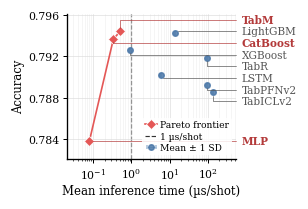

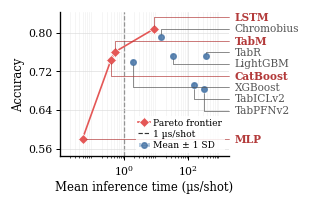

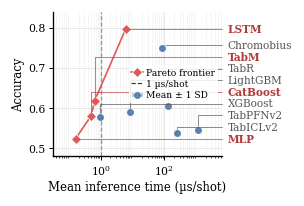

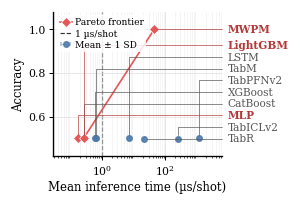

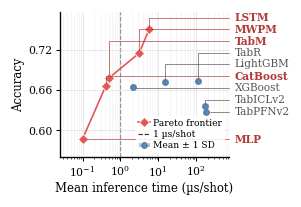

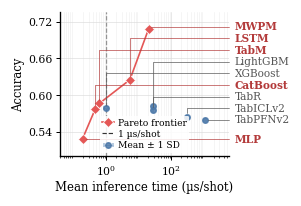

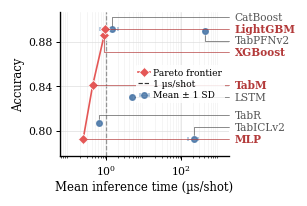

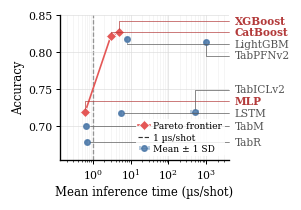

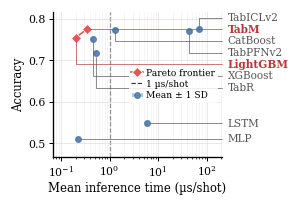

In [3]:
from paretoset import paretoset
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.text import Text
from matplotlib.ticker import LogLocator, NullFormatter, MaxNLocator, LogFormatterMathtext
import re

# Physical size for each independent LaTeX panel (inches).
PANEL_SIZE = (2.6, 1.8)
DECODER_NAMES = {
    "mlp": "MLP", "lstm": "LSTM", "tabm": "TabM", "tabr": "TabR",
    "tabiclv2": "TabICLv2", "tabpfnv2": "TabPFNv2",
    "catboost": "CatBoost", "lightgbm": "LightGBM", "xgboost": "XGBoost",
    "mwpm": "MWPM", "chromobius": "Chromobius",
}
OUTPUT_DIR = Path("figures")
OUTPUT_DIR.mkdir(exist_ok=True)

# Keep only finite accuracies and positive times for the logarithmic axis.
valid_results = results.dropna(
    subset=["accuracy", "inference_mean_us_per_shot"]
).copy()
valid_results = valid_results.loc[
    np.isfinite(valid_results["accuracy"])
    & np.isfinite(valid_results["inference_mean_us_per_shot"])
    & valid_results["inference_mean_us_per_shot"].gt(0)
].copy()
valid_results["pareto_optimal"] = False

for _, indices in valid_results.groupby("dataset", sort=False).groups.items():
    group = valid_results.loc[indices]
    valid_results.loc[indices, "pareto_optimal"] = paretoset(
        group[["accuracy", "inference_mean_us_per_shot"]], sense=["max", "min"]
    )

pareto_frontiers = valid_results.loc[valid_results["pareto_optimal"]].copy()
display(
    pareto_frontiers[
        ["dataset", "decoder", "accuracy", "inference_mean_us_per_shot"]
    ].sort_values(["dataset", "inference_mean_us_per_shot"])
)

plt.rcdefaults()
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 7,
    "axes.labelsize": 7,
    "axes.titlesize": 8,
    "legend.fontsize": 6,
    "xtick.labelsize": 6.5,
    "ytick.labelsize": 6.5,
    "figure.dpi": 120,
    "savefig.dpi": 300,
})


def label_box(annotation, renderer):
    # Annotation.get_window_extent also includes the leader line's bounding
    # box, which spans back to the annotated point; only the text matters here.
    annotation.update_positions(renderer)
    return Text.get_window_extent(annotation, renderer)


datasets = valid_results["dataset"].drop_duplicates().tolist()
for dataset in datasets:
    fig, ax = plt.subplots(figsize=PANEL_SIZE)
    # Reserve a fixed label column beside the plot.
    fig.subplots_adjust(left=0.21, right=0.75, bottom=0.21, top=0.88)
    data = valid_results.loc[valid_results["dataset"] == dataset]
    frontier = pareto_frontiers.loc[
        pareto_frontiers["dataset"] == dataset
    ].sort_values("inference_mean_us_per_shot")

    timing_std = data["inference_std_us_per_shot"].fillna(0)
    ax.errorbar(
        data["inference_mean_us_per_shot"],
        data["accuracy"],
        xerr=[
            timing_std.clip(upper=data["inference_mean_us_per_shot"] * 0.99),
            timing_std,
        ],
        fmt="o",
        markersize=3.2,
        color="#4C78A8",
        ecolor="#9BB7D4",
        elinewidth=0.6,
        capsize=1.3,
        alpha=0.85,
        label="Mean ± 1 SD",
        zorder=2,
    )
    ax.plot(
        frontier["inference_mean_us_per_shot"],
        frontier["accuracy"],
        marker="D",
        markersize=4,
        linewidth=1.0,
        color="#E45756",
        markerfacecolor="#E45756",
        markeredgecolor="white",
        markeredgewidth=0.45,
        label="Pareto frontier",
        zorder=3,
    )
    ax.axvline(
        1, color="#333333", linestyle="--", linewidth=0.7,
        label="1 µs/shot", zorder=1,
    )
    ax.set_xscale("log")
    ax.margins(x=0.18, y=0.16)
    ax.set_xlabel("Mean inference time (µs/shot)", labelpad=2)
    ax.xaxis.set_major_locator(LogLocator(base=10, numticks=4))
    # Power-of-ten labels make the base-10 logarithmic scale explicit.
    ax.xaxis.set_major_formatter(LogFormatterMathtext(base=10, labelOnlyBase=True))
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.yaxis.set_major_locator(MaxNLocator(nbins=4))
    ax.tick_params(which="major", length=2.5, width=0.6, pad=2)
    ax.tick_params(which="minor", length=1.3, width=0.4)
    ax.set_ylabel("Accuracy", labelpad=2)
    # ax.set_title(dataset, pad=4)
    ax.grid(True, which="major", axis="both", color="#D9D9D9", linewidth=0.35)
    ax.grid(True, which="minor", axis="x", color="#EEEEEE", linewidth=0.35)
    ax.spines[["top", "right"]].set_visible(False)
    handles, legend_labels = ax.get_legend_handles_labels()
    ax.legend(
        handles, legend_labels, loc="best",
        ncol=1, frameon=True, framealpha=0.85, edgecolor="none",
        fontsize=5.5, handlelength=1.3, handletextpad=0.35,
        labelspacing=0.25, borderpad=0.3, borderaxespad=0.4,
    )

    # Order labels by screen height and enforce a minimum gap. This always has
    # room for the current decoder count, even when several accuracies coincide.
    fig.canvas.draw()
    ordered = data.sort_values(["accuracy", "inference_mean_us_per_shot", "decoder"])
    point_pixels = ax.transData.transform(
        ordered[["inference_mean_us_per_shot", "accuracy"]].to_numpy()
    )
    desired_y = ax.transAxes.inverted().transform(point_pixels)[:, 1]
    count = len(ordered)
    min_gap = 7.0 / (ax.get_window_extent().height * 72 / fig.dpi)
    assert min_gap * max(count - 1, 0) <= 0.92, "Increase panel height for decoder labels"
    label_y = np.clip(desired_y, 0.04, 0.96)
    for i in range(1, count):
        label_y[i] = max(label_y[i], label_y[i - 1] + min_gap)
    if count and label_y[-1] > 0.96:
        label_y[-1] = 0.96
        for i in range(count - 2, -1, -1):
            label_y[i] = min(label_y[i], label_y[i + 1] - min_gap)

    annotations = []
    for (_, row), y in zip(ordered.iterrows(), label_y):
        is_pareto = row["pareto_optimal"]
        color = "#B33A3A" if is_pareto else "#555555"
        annotation = ax.annotate(
            DECODER_NAMES.get(row["decoder"], row["decoder"]),
            xy=(row["inference_mean_us_per_shot"], row["accuracy"]),
            xycoords="data", xytext=(1.035, y), textcoords="axes fraction",
            ha="left", va="center", fontsize=6.3,
            fontweight="bold" if is_pareto else "normal", color=color,
            arrowprops={
                "arrowstyle": "-", "color": color, "lw": 0.4,
                "shrinkA": 1.5, "shrinkB": 2,
                "connectionstyle": "angle,angleA=0,angleB=90,rad=0",
            },
            annotation_clip=False, zorder=4,
        )
        annotations.append(annotation)

    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    boxes = [label_box(annotation, renderer) for annotation in annotations]
    assert all(
        not boxes[i].overlaps(boxes[j])
        for i in range(len(boxes)) for j in range(i + 1, len(boxes))
    ), f"Overlapping labels in {dataset}"
    assert all(
        fig.bbox.contains(box.x0, box.y0) and fig.bbox.contains(box.x1, box.y1)
        for box in boxes
    ), f"Clipped label in {dataset}"
    # Fixed canvas preserves identical panel dimensions across all datasets.
    stem = re.sub(r"[^A-Za-z0-9]+", "_", dataset).strip("_")
    fig.savefig(OUTPUT_DIR / f"{stem}.pdf", facecolor="white")
    fig.savefig(OUTPUT_DIR / f"{stem}.png", dpi=400, facecolor="white")
    plt.show()
    plt.close(fig)
